# Week 3 - handwritten digits problem

## Setting up

The python package `scikit-learn` contains a data set of handwritten digits that were transformed to 8 by 8 matrices, where each element of the matrix corresponds to a pixel on a 8 by 8 grid and the value of the element indicates a grayscale value.
To use the data we have to import the `load_digits` function.

In [6]:
!pip install scikit-learn
!pip install torch torchvision torchaudio

     |████████████████████████████████| 150.6 MB 214 kB/s eta 0:00:011    |██████████████████████▏         | 104.3 MB 377 kB/s eta 0:02:03
     |████████████████████████████████| 1.7 MB 1.9 MB/s eta 0:00:01
     |████████████████████████████████| 3.4 MB 1.3 MB/s eta 0:00:01


In [16]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits

In [9]:
digits = load_digits()
digits.images

array([[[ 0.,  0.,  5., ...,  1.,  0.,  0.],
        [ 0.,  0., 13., ..., 15.,  5.,  0.],
        [ 0.,  3., 15., ..., 11.,  8.,  0.],
        ...,
        [ 0.,  4., 11., ..., 12.,  7.,  0.],
        [ 0.,  2., 14., ..., 12.,  0.,  0.],
        [ 0.,  0.,  6., ...,  0.,  0.,  0.]],

       [[ 0.,  0.,  0., ...,  5.,  0.,  0.],
        [ 0.,  0.,  0., ...,  9.,  0.,  0.],
        [ 0.,  0.,  3., ...,  6.,  0.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.]],

       [[ 0.,  0.,  0., ..., 12.,  0.,  0.],
        [ 0.,  0.,  3., ..., 14.,  0.,  0.],
        [ 0.,  0.,  8., ..., 16.,  0.,  0.],
        ...,
        [ 0.,  9., 16., ...,  0.,  0.,  0.],
        [ 0.,  3., 13., ..., 11.,  5.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.]],

       ...,

       [[ 0.,  0.,  1., ...,  1.,  0.,  0.],
        [ 0.,  0., 13., ...,  2.,  1.,  0.],
        [ 0.,  0., 16., ..., 16.,  5.,  0.

For this practical, we will mainly need the following components:

- `digits.images` is a 3-dimensional array (1797, 8, 8). The first dimension corresponds to the individual digits, each of which is saved as an $8\times 8$ matrix
- `digits.data`is a 2-dimensional arrray (1797, 64) that holds the same data as the `digits.images` only stored as a vector of length 64 instead of an 8 by 8 matrix
- `digits.target` is a one-dimensional array of size 1797 that contains the actual numbers encoded in the images.

1. Using `plt.imshow` and `digits.images` produce a few example images and compare these produced images to actual numbers stored in `digits.target`.

In [19]:
plt.imshow

<function matplotlib.pyplot.imshow(X, cmap=None, norm=None, *, aspect=None, interpolation=None, alpha=None, vmin=None, vmax=None, origin=None, extent=None, interpolation_stage=None, filternorm=True, filterrad=4.0, resample=None, url=None, data=None, **kwargs)>

In [17]:
digits = load_digits()
X = digits.data  
y = digits.target  


2. Perform principal component analysis (PCA) to reduce the 64-dimensional data to a single principal component. Construct grouped boxplots for the first principal component. By visually inspecting the boxplots, comment on the "predictive power" of the first principal component for the true label (actual digit).

<Figure size 720x432 with 0 Axes>

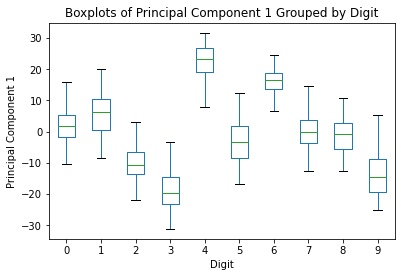

In [18]:

pca = PCA(n_components=1)
X_pca = pca.fit_transform(X)


df = pd.DataFrame({'Principal Component 1': X_pca.flatten(), 'Digit': y})

# Construct grouped boxplots
plt.figure(figsize=(10, 6))
df.boxplot(by='Digit', column=['Principal Component 1'], grid=False, showfliers=False)
plt.title("Boxplots of Principal Component 1 Grouped by Digit")
plt.suptitle("")  # Suppress the default title
plt.xlabel("Digit")
plt.ylabel("Principal Component 1")
plt.xticks(rotation=0)
plt.show()

3. Increase the number of principal components to 2. Produce a scatter plot of the transformed data, coloring each point according to its digit label (0-9). Using this visualisation, comment whether the different digit classes are separable in the 2D space.

<ipython-input-21-8735cb2e58b6>:23: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(1, 2, 2)


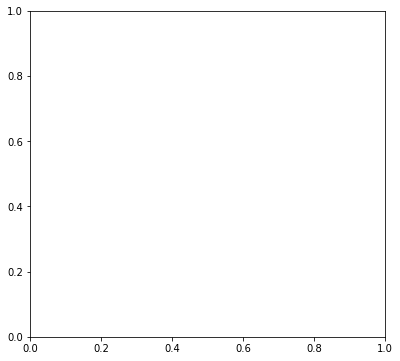

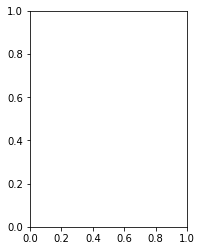

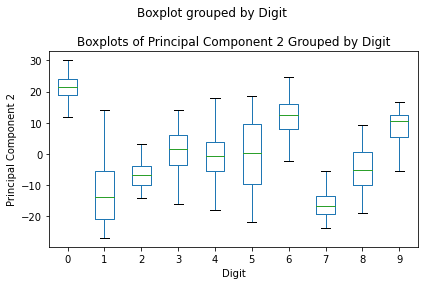

In [21]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Create a DataFrame for easier plotting
df = pd.DataFrame({
    'Principal Component 1': X_pca[:, 0],
    'Principal Component 2': X_pca[:, 1],
    'Digit': y
})

# Construct grouped boxplots for Principal Component 1
plt.figure(figsize=(14, 6))

# Boxplot for Principal Component 1
plt.subplot(1, 2, 1)
df.boxplot(by='Digit', column=['Principal Component 1'], grid=False, showfliers=False)
plt.title("Boxplots of Principal Component 1 Grouped by Digit")
plt.suptitle("")  # Suppress the default title
plt.xlabel("Digit")
plt.ylabel("Principal Component 1")

# Boxplot for Principal Component 2
plt.subplot(1, 2, 2)
df.boxplot(by='Digit', column=['Principal Component 2'], grid=False, showfliers=False)
plt.title("Boxplots of Principal Component 2 Grouped by Digit")
plt.xlabel("Digit")
plt.ylabel("Principal Component 2")

# Show the plots
plt.tight_layout()
plt.show()

4. Using the **proportion of variance explained (PVE)** and the **cumulative PVE**, choose the optimal number of principal components for this data set.

5. Train an autoencoder on the dataset to reduce its 64-dimensional feature space to a latent representation of your chosen dimensionality. Explore the effect of the number of hidden layers and activation functions on your analysis.